In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [3]:
df = pd.read_excel("Online Retail.xlsx")
df = df.drop_duplicates().copy()

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

data = df[
    (df["UnitPrice"] > 0) &
    (df["Quantity"] > 0) &
    (df["InvoiceDate"].notna()) &
    (df["StockCode"].notna())
].copy()

data["StockCode"] = data["StockCode"].astype(str)
data["Month"] = data["InvoiceDate"].dt.month
data["Hour"] = data["InvoiceDate"].dt.hour
data["DayOfWeek"] = data["InvoiceDate"].dt.dayofweek

sample = data[
    ["UnitPrice", "Quantity", "StockCode",
     "Month", "Hour", "DayOfWeek"]
].sample(
    n=min(20000, len(data)),
    random_state=42
).reset_index(drop=True)

print("Sample size:", len(sample))

Sample size: 20000


In [4]:
def estimate_dml(sample, controls):
    T = sample["UnitPrice"].to_numpy()
    Y = sample["Quantity"].to_numpy()
    X = sample[controls].copy()

    kf = KFold(n_splits=2, shuffle=True, random_state=42)
    t_res = np.zeros(len(sample))
    y_res = np.zeros(len(sample))

    for train_idx, test_idx in kf.split(X):
        transformers = []

        if "StockCode" in controls:
            transformers.append((
                "product",
                OneHotEncoder(handle_unknown="ignore"),
                ["StockCode"]
            ))

        time_cols = [c for c in controls if c != "StockCode"]
        if time_cols:
            transformers.append(("time", "passthrough", time_cols))

        model_t = make_pipeline(
            ColumnTransformer(transformers),
            Ridge(alpha=10.0)
        )
        model_y = make_pipeline(
            ColumnTransformer(transformers),
            Ridge(alpha=10.0)
        )

        model_t.fit(X.iloc[train_idx], T[train_idx])
        model_y.fit(X.iloc[train_idx], Y[train_idx])

        t_res[test_idx] = T[test_idx] - model_t.predict(X.iloc[test_idx])
        y_res[test_idx] = Y[test_idx] - model_y.predict(X.iloc[test_idx])

    denominator = np.mean(t_res ** 2)
    if denominator <= 1e-10:
        return np.nan

    return np.mean(t_res * y_res) / denominator


results = []

for n in [5000, 10000, 20000]:
    subset = sample.sample(n=min(n, len(sample)), random_state=42)

    estimate = estimate_dml(
        subset,
        ["StockCode", "Month", "Hour", "DayOfWeek"]
    )

    results.append({
        "SampleSize": len(subset),
        "PreliminaryCoefficient": estimate
    })

robustness = pd.DataFrame(results)
display(robustness)

,SampleSize,PreliminaryCoefficient
0,5000,-0.001549
1,10000,-0.002275
2,20000,-0.003001


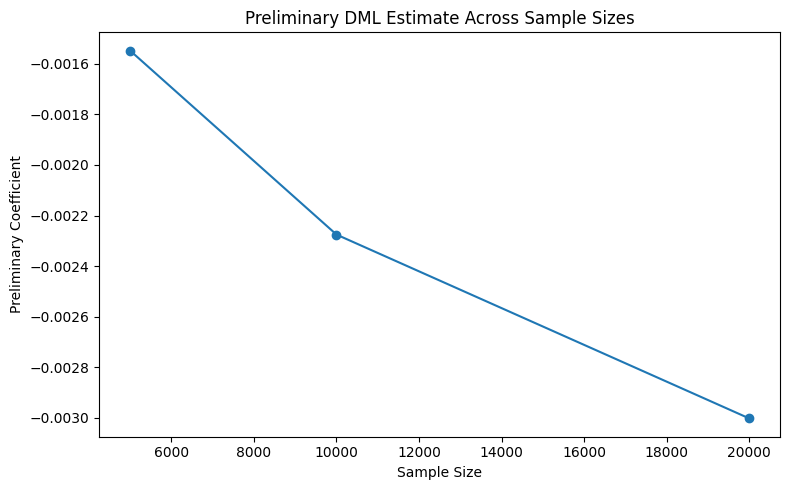

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(
    robustness["SampleSize"],
    robustness["PreliminaryCoefficient"],
    marker="o"
)
plt.title("Preliminary DML Estimate Across Sample Sizes")
plt.xlabel("Sample Size")
plt.ylabel("Preliminary Coefficient")
plt.tight_layout()
plt.show()

In [6]:
robustness.to_csv(
    "day16_dml_robustness_summary.csv",
    index=False
)

print("Day 16 report saved!")

Day 16 report saved!


In [7]:
files.download("day16_dml_robustness_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>